# Harp clock step

Twice per session, 1,280 s apart, the Harp Behavior board's timestamps run a few
ppm fast for ~4–5 min and then step back on one row, taking back the 1–6 ms they
gained. The cameras keep exposing on time; only the board's timestamps move.

This is the timestamping bug in
[harp-tech/protocol#48](https://github.com/harp-tech/protocol/issues/48), fixed in
the atxmega core 1.14 (our report:
[dynamic-foraging-task#1768](https://github.com/AllenNeuralDynamics/dynamic-foraging-task/issues/1768)).
Boards on older cores keep producing it.

1. **What it looks like**: one session's rows around a step.
2. **The ramp**: Harp − camera time, with and without the normal clock drift.
3. **Across sessions**: how big, how often, which firmware.
4. **A fix**: spread the step over the frames before it, and what that leaves.

Data: `s3://aind-open-data` over HTTPS (~150 MB per session), cached in
`VTQ_CACHE` (default `./video_timing_qc_data`). Section 3 reads
`clock_step_scan.csv`: one row per scanned session, from running
`find_clock_steps` (below) on each session's camera trigger log.

In [1]:
import os
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aind_dynamic_foraging_behavior_video_analysis import video_timing_qc as vtq

S3 = "https://aind-open-data.s3.amazonaws.com"
CACHE = Path(os.environ.get("VTQ_CACHE", "video_timing_qc_data"))
LOG = "behavior/raw.harp/BehaviorEvents/Event_94.bin"

# One colour per role, in every figure.
AS_WRITTEN = "#eb6834"  # Harp column as written
REPAIRED = "#2a78d6"    # after repair_clock_steps
OLD = "#1baf7a"         # old platform (dynamic-foraging-task)
NEW = "#eda100"         # new platform (Aind.Behavior.DynamicForaging)
CAMERA = "0.45"         # camera clock, step markers
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "0.9",
    "lines.linewidth": 2,
})


def fetch(key):
    # Return a local copy of an aind-open-data object, downloading once.
    path = CACHE / key
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print("downloading", key)
        urllib.request.urlretrieve(f"{S3}/{key}", path)
    return path


def load(session, csv):
    # The camera's timing table (Harp, frame number, camera time per row).
    return vtq.load_video_timing(fetch(f"{session}/behavior-videos/{csv}"))


def find_clock_steps(harp, threshold=0.3e-3):
    # Rows whose Harp step is 0.3-10 ms short of a frame interval, with the
    # next step on time: the snap back at the end of a ramp. Returns the rows
    # and each one's shortfall (the ramp's peak), in s.
    harp = np.asarray(harp, dtype="float64")
    ifi = vtq.frame_interval(harp)
    dev = np.diff(harp) - ifi
    nxt = np.append(dev[1:], 0)
    i = np.flatnonzero((dev < -threshold) & (dev > -10e-3) & (np.abs(nxt) < threshold))
    return i + 1, -dev[i]


def offset_from_camera(timing, steps, every=200):
    # Harp - camera time with the normal clock drift removed: a line fitted
    # away from the ramps (the 6 min before each step). Every ``every``-th row.
    harp = timing["harp_time_raw"].to_numpy()[::every]
    camera = timing["camera_time"].to_numpy()[::every]
    minutes = (camera - camera[0]) / 60
    offset = harp - camera
    steady = np.all([(minutes < minutes[s // every] - 6) | (minutes >= minutes[s // every])
                     for s in steps], axis=0)
    slope, intercept = np.polyfit(minutes[steady], offset[steady], 1)
    return minutes, offset, intercept + slope * minutes, slope / 60 * 1e6

## 1. What it looks like

Three examples on the old platform: the two from the issue and the largest we
have found (`447_3D`, ~5 ms). Each step row is a single Harp step that is
**short** (here negative) while the camera clock steps 2 ms and no frame is
lost.

In [2]:
SESSIONS = {
    "800886 (446_8D)": ("behavior_800886_2025-08-26_13-15-13", "bottom_camera.csv"),
    "751181 (322_EPHYS4)": ("behavior_751181_2025-02-26_11-51-15", "BottomCamera/metadata.csv"),
    "866647 (447_3D)": ("behavior_866647_2026-09-18_14-10-11", "BottomCamera/metadata.csv"),
}
examples = {}
for name, (session, csv) in SESSIONS.items():
    timing = load(session, csv)
    steps, peaks = find_clock_steps(timing["harp_time_raw"])
    examples[name] = timing, steps, peaks

rows = []
for name, (timing, steps, peaks) in examples.items():
    harp, cam, frames = (timing[c].to_numpy() for c in ("harp_time_raw", "camera_time", "frame_number"))
    for r, p in zip(steps, peaks):
        rows.append({"session": name, "row": r, "Harp time (s)": harp[r],
                     "Harp step (ms)": (harp[r] - harp[r - 1]) * 1e3,
                     "camera step (ms)": (cam[r] - cam[r - 1]) * 1e3,
                     "frame step": frames[r] - frames[r - 1],
                     "peak (ms)": p * 1e3})
step_table = pd.DataFrame(rows)
step_table["Harp s mod 256"] = step_table["Harp time (s)"].round().astype(int) % 256
step_table.style.format({"Harp time (s)": "{:.6f}", "Harp step (ms)": "{:+.3f}",
                         "camera step (ms)": "{:+.3f}", "peak (ms)": "{:.2f}"}).hide()

session,row,Harp time (s),Harp step (ms),camera step (ms),frame step,peak (ms),Harp s mod 256
800886 (446_8D),1581938,3975936.999456,-1.280,+2.003,1,3.28,1
800886 (446_8D),2221947,3977217.000928,-1.312,+2.000,1,3.31,1
751181 (322_EPHYS4),856133,5876481.001120,-0.512,+1.996,1,2.51,1
751181 (322_EPHYS4),1496139,5877761.000064,-0.576,+2.003,1,2.58,1
866647 (447_3D),873136,26520321.000000,-2.944,+2.000,1,4.94,1
866647 (447_3D),1513149,26521601.000608,-3.104,+1.999,1,5.10,1


Each pair is 1,280 s apart, and every step lands on a Harp second ≡ 1 (mod
256), as in all 74 steps found so far (and in the examples in #48).

## 2. The ramp

Both clocks timestamp the same exposures, so `Harp − camera` shows any
difference in how they run. The two crystals never run at exactly the same rate,
so the offset grows by ~80 ms over a session (**left**). That is normal and
harmless. Fitting that line away from the ramps and subtracting it (**right**)
leaves the anomaly: 4–5 min of the Harp clock running fast, then the snap back
at the step (dashed).

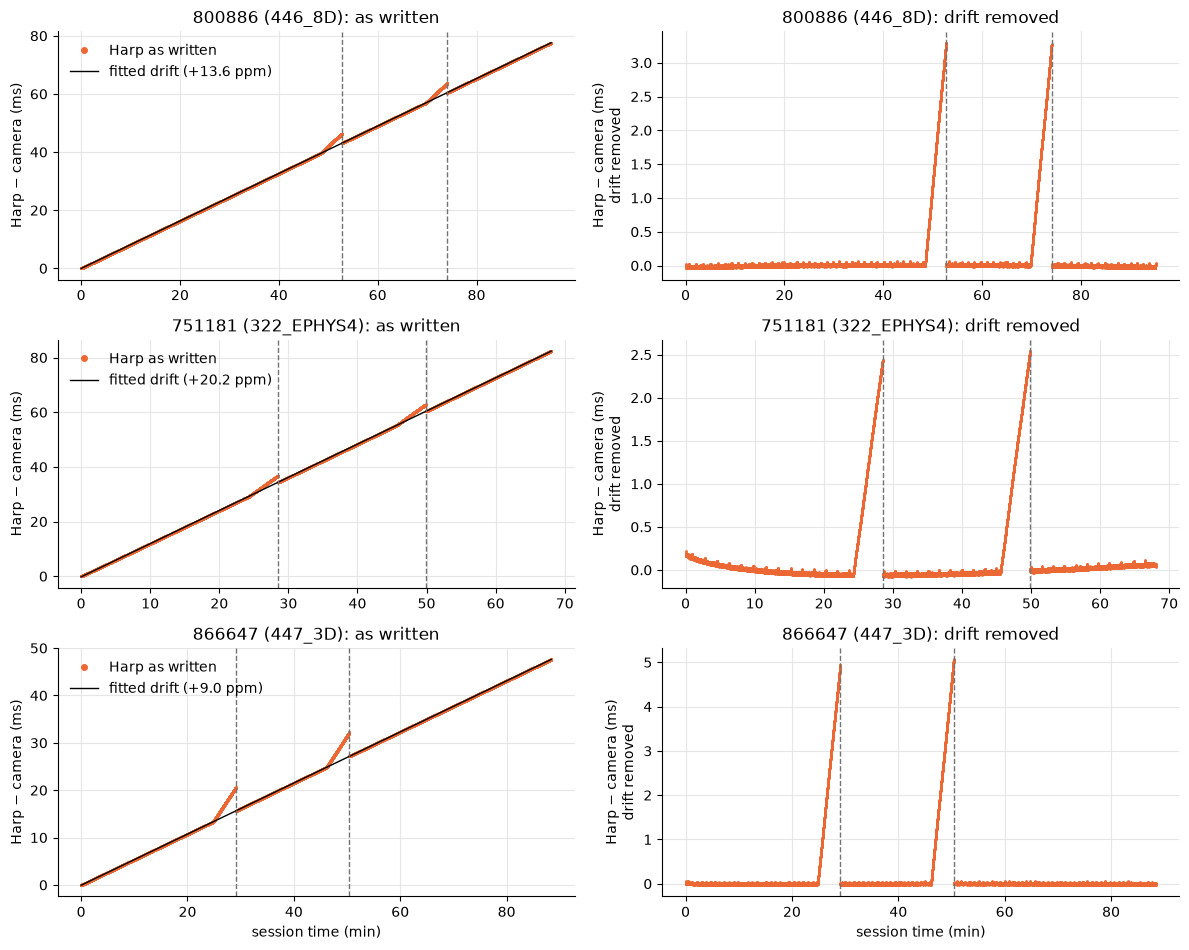

In [3]:
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 3.2 * len(examples)))
for row, (name, (timing, steps, peaks)) in zip(axes, examples.items()):
    minutes, offset, fit, ppm = offset_from_camera(timing, steps)
    row[0].plot(minutes, (offset - offset[0]) * 1e3, ".", color=AS_WRITTEN, markersize=2,
                label="Harp as written")
    row[0].plot(minutes, (fit - offset[0]) * 1e3, "-", color="k", linewidth=1,
                label=f"fitted drift ({ppm:+.1f} ppm)")
    row[0].set(title=f"{name}: as written", ylabel="Harp − camera (ms)")
    row[0].legend(loc="upper left", markerscale=4, frameon=False)
    row[1].plot(minutes, (offset - fit) * 1e3, ".", color=AS_WRITTEN, markersize=2)
    row[1].set(title=f"{name}: drift removed", ylabel="Harp − camera (ms)\ndrift removed")
    for ax in row:
        for s in steps:
            ax.axvline(minutes[s // 200], color=CAMERA, linestyle="--", linewidth=1)
for ax in axes[-1]:
    ax.set_xlabel("session time (min)")
fig.tight_layout()

The step takes back what the ramp gained: the curve returns to the same
baseline after each step, so **nothing accumulates** across the session. The
peak equals the step's shortfall from one frame interval, which is how the scan
below measures it from the trigger log alone.

## 3. Across sessions

440 sessions (Feb 2025 – Oct 2026): the 28 sessions excluded in the FIP video
screen, recent sessions on both platforms (latest 15 per FIP rig, latest 2 per
other rig, every old-platform session since 2026-09-25), and every
new-platform session. The scan reads the camera trigger log (`Event_94.bin` on
the old platform, `Behavior.harp/Behavior_94.bin` on the new) and ignores its
first and last 5 s (the new platform has an extra trigger at start).

          count  mean   std   min   25%   50%   75%   max
platform                                                 
new         7.0  1.67  0.77  1.04  1.21  1.55  1.69  3.31
old        39.0  2.92  1.44  0.91  1.86  2.58  3.26  5.71


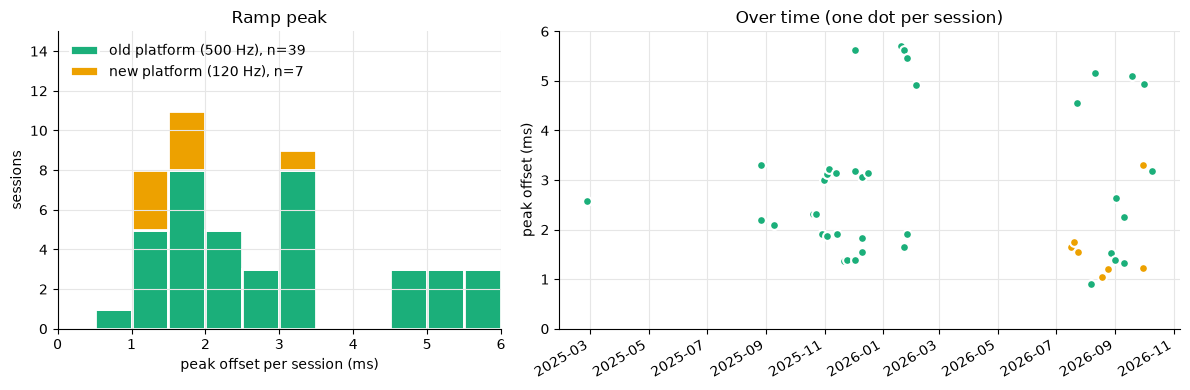

In [4]:
scan = pd.read_csv("clock_step_scan.csv", parse_dates=["date"],
                   dtype={"behavior_core": str, "behavior_fw": str})
per_session = scan[scan.clock_steps > 0]
colours = {"old": OLD, "new": NEW}
labels = {"old": "old platform (500 Hz)", "new": "new platform (120 Hz)"}

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
bins = np.arange(0, 6.01, 0.5)
bottom = np.zeros(len(bins) - 1)
for p in ["old", "new"]:
    h, _ = np.histogram(per_session.peak_ms[per_session.platform == p], bins)
    a.bar(bins[:-1], h, width=0.5, bottom=bottom, align="edge", color=colours[p],
          edgecolor="white", linewidth=2, label=f"{labels[p]}, n={(per_session.platform == p).sum()}")
    bottom += h
a.set(xlabel="peak offset per session (ms)", ylabel="sessions", xlim=(0, 6),
      ylim=(0, bottom.max() + 4), title="Ramp peak")
a.legend(loc="upper left", frameon=False)
for p in ["old", "new"]:
    d = per_session[per_session.platform == p]
    b.scatter(d.date, d.peak_ms, s=40, color=colours[p], edgecolor="white", linewidth=1.5, zorder=3)
b.set(ylabel="peak offset (ms)", ylim=(0, 6), title="Over time (one dot per session)")
plt.setp(b.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()

print(per_session.groupby("platform").peak_ms.describe().round(2).to_string())

Peaks run 0.9–5.7 ms (median 2.3 ms) and stay in a band per rig (e.g. `447_3D`
~5 ms, `447_2D` < 2 ms). The two steps in a session differ by a median of
0.1 ms. Gaps in time are where nothing was scanned.

**By firmware.** Only the new platform logs the board's version registers.
Sessions on core 1.15 (which includes the #48 fix) have had no step so far.

In [5]:
(scan[scan.platform == "new"]
 .groupby(["behavior_core", "behavior_fw"])
 .agg(sessions=("name", "size"), with_step=("clock_steps", lambda s: int((s > 0).sum())),
      first=("date", lambda d: d.min().date()), last=("date", lambda d: d.max().date()))
 .rename_axis(["Behavior core", "firmware"]))

,,sessions,with_step,first,last
Behavior core,firmware,,,,
1.11,3.1,34,2,2026-09-28,2026-10-20
1.13,3.2,110,5,2026-05-31,2026-10-07
1.15,3.3,58,0,2026-10-07,2026-10-20


Old-platform rigs don't log versions; a step shows the board was unfixed that
day. The latest is `447_3A` on 2026-10-09.

## 4. A fix: spread the step over the frames before it

The ramp is in the Behavior board's **timestamps**, so every event that board
timestamps during a ramp (licks, digital and analog inputs, camera triggers)
carries the same offset. Keeping the Harp column as written keeps video aligned
with those events; only the step itself has to go, because time running
backward breaks downstream code (`merge_asof`, `kinematics_filter`).

There is only **one** backward step, but it can't be fixed by changing that row
alone. The rows before the step are ahead by the peak `P`; the rows from the step
on are correct. Keep both sides as written, and the time between row `r − m − 1`
(before the ramp's end) and row `r` (the step) is fixed at `(m + 1) · frame − P`,
whatever is done to the `m` rows in between. So the steps between them average
`frame − P / (m + 1)`. With 800886 (`P` = 3.28 ms, frame = 2 ms):

| rows moved `m` | steps sharing `P` | each step | |
|---|---|---|---|
| 0 (as written) | 1 | −1.28 ms | backward |
| 1 (midpoint, as for glitches) | 2 | +0.36 ms | forward, but fails `harp_evenly_spaced` |
| 4 | 5 | +1.34 ms | within half a frame |

`repair_clock_steps` picks the smallest `m` that keeps every step within half a
frame of normal (so `harp_evenly_spaced` passes) and moves those rows linearly:

- row `r − m + k − 1` moves earlier by `P · k / (m + 1)` for `k = 1 … m`,
- `m` is the smallest number with `P / (m + 1) < frame / 2` (1–6 rows at
  500 Hz for peaks of 1–6 ms).

All other rows keep their Harp time.

In [6]:
def repair_clock_steps(harp):
    # Harp times with each clock step spread over the frames before it.
    # Returns the repaired times, the step rows, and the rows changed.
    t = np.asarray(harp, dtype="float64").copy()
    ifi = vtq.frame_interval(t)
    steps, peaks = find_clock_steps(t)
    changed = []
    for r, p in zip(steps, peaks):
        m = int(np.floor(2 * p / ifi)) + 1
        k = np.arange(1, m + 1)
        t[r - m + k - 1] -= p * k / (m + 1)
        changed.extend(r - m + k - 1)
    return t, steps, np.array(changed, dtype=int)


rows = []
for name, (timing, steps, peaks) in examples.items():
    raw = timing["harp_time_raw"].to_numpy()
    fixed, steps, changed = repair_clock_steps(raw)
    examples[name] = timing, steps, peaks, fixed
    for label, t in [("as written", raw), ("repaired", fixed)]:
        rows.append({"session": name, "Harp": label,
                     "smallest step (ms)": np.diff(t).min() * 1e3,
                     "time always increases": bool((np.diff(t) > 0).all()),
                     "harp_evenly_spaced": bool(vtq.check_harp_evenly_spaced(t)["passed"]),
                     "rows changed": 0 if label == "as written" else len(changed),
                     "largest change (ms)": np.abs(t - raw).max() * 1e3})
pd.DataFrame(rows).style.format({"smallest step (ms)": "{:+.3f}", "largest change (ms)": "{:.2f}"}).hide()

session,Harp,smallest step (ms),time always increases,harp_evenly_spaced,rows changed,largest change (ms)
800886 (446_8D),as written,-1.312,False,False,0,0.00
800886 (446_8D),repaired,+1.322,True,True,8,2.65
751181 (322_EPHYS4),as written,-0.576,False,False,0,0.00
751181 (322_EPHYS4),repaired,+1.340,True,True,6,1.93
866647 (447_3D),as written,-3.104,False,False,0,0.00
866647 (447_3D),repaired,+1.160,True,True,11,4.37


Around each step: the Harp step per row (**top**), and the offset from the
camera clock with the normal drift removed (**bottom**), as written and
repaired. The repair only touches the last few frames of the ramp: it removes
the backward step and slightly reduces the offset there; everywhere else the two
lines coincide.

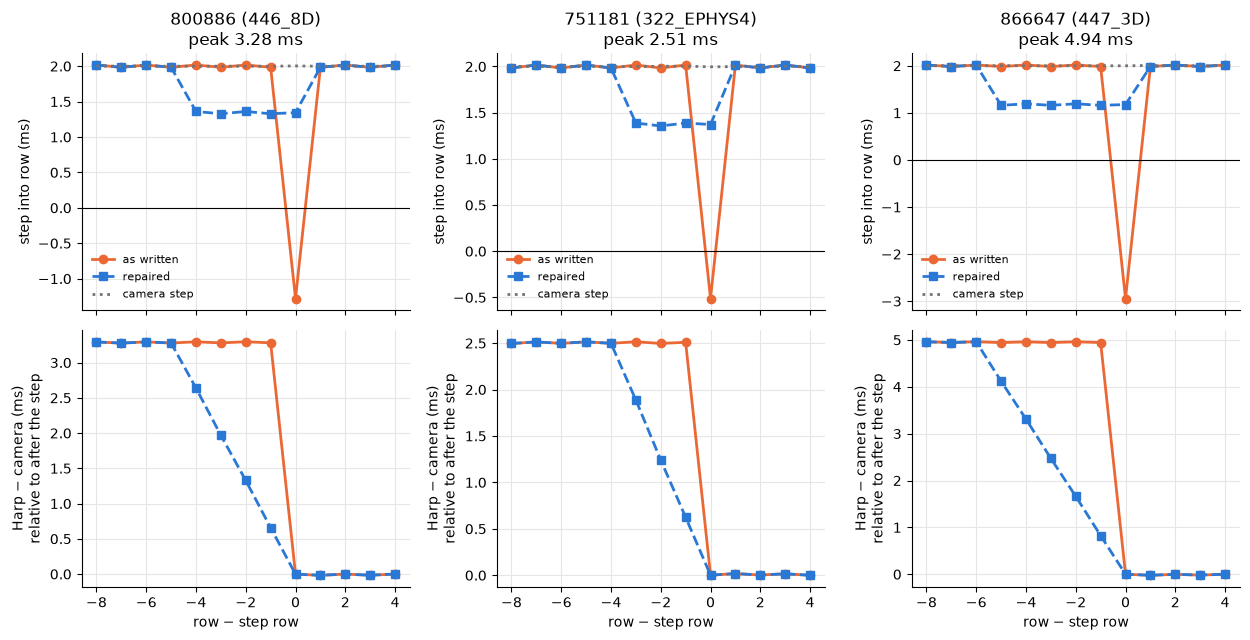

In [7]:
fig, axes = plt.subplots(2, len(examples), figsize=(4.2 * len(examples), 6.5), sharex=True)
for col, (name, (timing, steps, peaks, fixed)) in zip(axes.T, examples.items()):
    r = steps[0]
    window = np.arange(r - 8, r + 5)
    raw = timing["harp_time_raw"].to_numpy()
    camera = timing["camera_time"].to_numpy()
    _, _, _, ppm = offset_from_camera(timing, steps)
    for t, colour, label, style in [(raw, AS_WRITTEN, "as written", "o-"),
                                     (fixed, REPAIRED, "repaired", "s--")]:
        col[0].plot(window - r, np.diff(t)[window - 1] * 1e3, style, color=colour, label=label,
                    markersize=6)
        off = (t - camera)[window] - (raw - camera)[r + 4]
        off -= ppm * 1e-6 * (camera[window] - camera[r + 4])
        col[1].plot(window - r, off * 1e3, style, color=colour, label=label, markersize=6)
    col[0].plot(window - r, np.diff(camera)[window - 1] * 1e3, ":", color=CAMERA, label="camera step")
    col[0].axhline(0, color="k", linewidth=0.8)
    col[0].set(title=f"{name}\npeak {peaks[0] * 1e3:.2f} ms", ylabel="step into row (ms)")
    col[1].set(xlabel="row − step row", ylabel="Harp − camera (ms)\nrelative to after the step")
    col[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()

**What the repair leaves.** Relative to the camera clock (and to Harp devices
that were not ramping), frames inside a ramp window are still off by up to that
session's peak: at most 5.7 ms (≈3 frames at 500 Hz), median 2.3 ms, rising
linearly from 0 at the start of the ramp. Outside the two ~4–5 min windows the
offset is 0. Relative to events timestamped by the same Behavior board, video
stays aligned, except for the `m` frames moved by the repair (≤ the peak, a few
ms, over ≤ 6 frames).

The fraction of each example session inside a ramp window:

In [8]:
rows = []
for name, (timing, steps, peaks, fixed) in examples.items():
    minutes, offset, fit, _ = offset_from_camera(timing, steps, every=1)
    in_ramp = (offset - fit) > 0.3e-3   # 0.3 ms above the drift line
    rows.append({"session": name, "minutes": minutes[-1],
                 "in ramp windows (min)": in_ramp.sum() / len(in_ramp) * minutes[-1],
                 "fraction of frames": in_ramp.mean(),
                 "peak (ms)": peaks.max() * 1e3})
pd.DataFrame(rows).style.format({"minutes": "{:.1f}", "in ramp windows (min)": "{:.1f}",
                                 "fraction of frames": "{:.1%}", "peak (ms)": "{:.2f}"}).hide()

session,minutes,in ramp windows (min),fraction of frames,peak (ms)
800886 (446_8D),95.1,7.8,8.2%,3.31
751181 (322_EPHYS4),68.0,7.4,10.9%,2.58
866647 (447_3D),88.4,8.0,9.1%,5.10


**To decide before adopting this:**
- Which events do analyses align video to? Behavior-board events (licks) share
  the ramp, so the repair keeps them aligned; sound-card or FIP events may not.
- Do other Harp devices ramp at the same seconds? If they all do, the residual
  offset is shared and disappears for cross-device alignment too.
- At 120 Hz, peaks under half a frame (4.2 ms) don't fail `harp_evenly_spaced`,
  so the QC currently passes those sessions as written; the repair still
  applies.